# Gaussain Mixture Models For Clustering

In [16]:
import matplotlib.cm as cm
import numpy as np
import pandas as pd
import plotly.io as pio

from IPython.display import display_html
from matplotlib import pyplot as plt
from plotly import express as px
from plotly import graph_objects as go
from plotly.subplots import make_subplots
from sklearn import datasets
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import (
    train_test_split, 
    GridSearchCV, 
)
from src.data import (
    loader as data_loader,
)
from src.data import (
    sample as data_sample,
    display_ as data_display,
)

## Utils

In [2]:
pio.renderers.default = "png"

## Data

### Cercles

Read: cercles3.txt


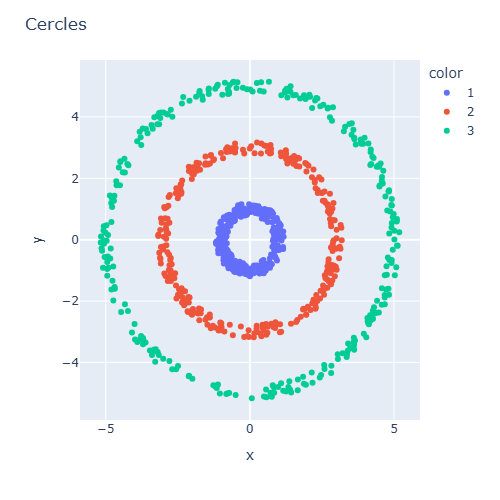

In [3]:
df_c = data_loader.load_cercles_ds()

# Plot data
fig = px.line(x=df_c["x1"], y=df_c["x2"], color=df_c["y"])
fig.update_traces(mode="markers")
fig.update_layout(title="Cercles", width=500)

### Noeuds

Read: noeud.txt


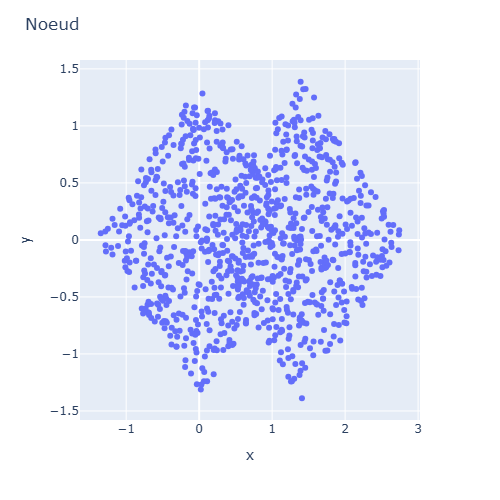

In [4]:
df_n = data_loader.load_noeud_ds()

# Plot data
fig = px.line(x=df_n["x1"], y=df_n["x2"])
fig.update_traces(mode="markers")
fig.update_layout(title="Noeud", width=500)

### Iris

### Gaussian mixtures

#### With same covariance per class 

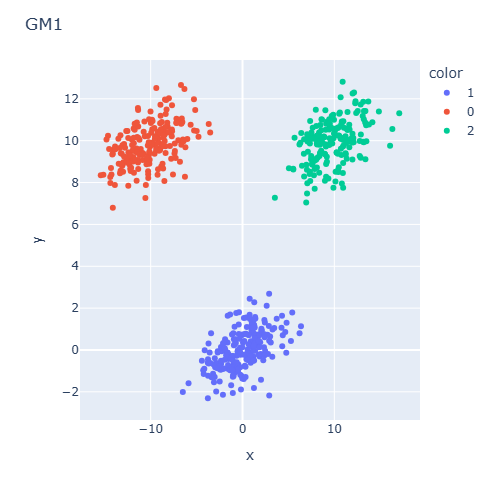

In [9]:
# Distributions Means
means = np.array([[-10, 10], [0, 0], [10, 10]])

# Distributions Covariances
cov = np.array([[5, 1], [1, 1]])
covs = [
    cov,
    cov,
    cov,
]

# Sample
df_gm1 = data_sample.generate_gaussian_mixture_sample(
    means=means, 
    covs=covs, 
    size=600, 
)

# Plot data
fig = px.line(x=df_gm1["x1"], y=df_gm1["x2"], color=df_gm1["y"])
fig.update_traces(mode="markers")
fig.update_layout(title="GM1", width=500)

#### With different covariance per class 

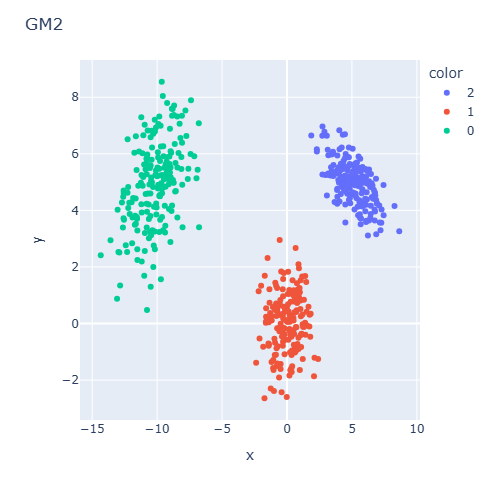

In [11]:
# Distributions Means
means = np.array([[-10, 5], [0, 0], [5, 5]])

# Distributions Covariances
covs = [
    np.array([[2, 1], [1, 2]]),
    np.array([[1, 0], [0, 1]]),
    np.array([[1.5, -0.5], [-0.5, 0.5]]),
]

# Sample
df_gm2 = data_sample.generate_gaussian_mixture_sample(
    means=means, 
    covs=covs, 
    size=600, 
)

# Plot data
fig = px.line(x=df_gm2["x1"], y=df_gm2["x2"], color=df_gm2["y"])
fig.update_traces(mode="markers")
fig.update_layout(title="GM2", width=500)

### Consolidated datasets

In [18]:
dict_df_ds = {
    "cercles": df_c,
    "noeud": df_n,
    "gm1": df_gm1,
    "gm2": df_gm2,
}
LIST_DS = [ds for ds in dict_df_ds]
N_DS = len(LIST_DS)
print(LIST_DS)

['cercles', 'noeud', 'gm1', 'gm2']


## Train/Test Split

In [19]:
def get_train_test_split(
    df: pd.DataFrame,
) -> dict:

    X_raw = df[["x1", "x2"]]

    # Train-Test Split
    X, X_test = train_test_split(
        X_raw,
        test_size=0.25,
        random_state=0,  # reproducibility
        shuffle=True,
    )
    dict_split = {
        "train": {"X": X},
        "test": {"X": X_test},
    }
    return dict_split


DICT_DS_SPLIT = {n: get_train_test_split(df=dict_df_ds[n]) for n in dict_df_ds}

In [20]:
list_temp = [
    {
        "name": n,
        "split": t,
        "X": DICT_DS_SPLIT[n][t]["X"].shape,
        "pct": DICT_DS_SPLIT[n][t]["X"].shape[0] / dict_df_ds[n].shape[0],
    }
    for n in DICT_DS_SPLIT.keys()
    for t in DICT_DS_SPLIT[n]
]
pd.DataFrame(list_temp)

,name,split,X,pct
0,cercles,train,"(675, 2)",0.75
1,cercles,test,"(225, 2)",0.25
2,noeud,train,"(750, 2)",0.75
3,noeud,test,"(250, 2)",0.25
4,gm1,train,"(450, 2)",0.75
5,gm1,test,"(150, 2)",0.25
6,gm2,train,"(450, 2)",0.75
7,gm2,test,"(150, 2)",0.25


#

## Gaussian Mixture Clustering

cf Model definition in @notes.pdf

### Scikit-learn classes documentation

The documentation below was obtained using help(GaussianMixture)

#### Classes

In [21]:
# help(GaussianMixture)

```
class GaussianMixture(sklearn.mixture._base.BaseMixture)
 |  GaussianMixture(
 |      n_components=1,
 |      *,
 |      covariance_type='full',
 |      tol=0.001,
 |      reg_covar=1e-06,
 |      max_iter=100,
 |      n_init=1,
 |      init_params='kmeans',
 |      weights_init=None,
 |      means_init=None,
 |      precisions_init=None,
 |      random_state=None,
 |      warm_start=False,
 |      verbose=0,
 |      verbose_interval=10
 |  )
```

#### Parameters

```
 |  Parameters
 |  ----------
 |  n_components : int, default=1
 |      The number of mixture components.
 |
 |  covariance_type : {'full', 'tied', 'diag', 'spherical'}, default='full'
 |      String describing the type of covariance parameters to use.
 |      Must be one of:
 |
 |      - 'full': each component has its own general covariance matrix.
 |      - 'tied': all components share the same general covariance matrix.
 |      - 'diag': each component has its own diagonal covariance matrix.
 |      - 'spherical': each component has its own single variance.
 |
 |      For an example of using `covariance_type`, refer to
 |      :ref:`sphx_glr_auto_examples_mixture_plot_gmm_selection.py`.
 |
 |  tol : float, default=1e-3
 |      The convergence threshold. EM iterations will stop when the
 |      lower bound average gain is below this threshold.
 |
 |  reg_covar : float, default=1e-6
 |      Non-negative regularization added to the diagonal of covariance.
 |      Allows to assure that the covariance matrices are all positive.
 |
 |  max_iter : int, default=100
 |      The number of EM iterations to perform.
 |
 |  n_init : int, default=1
 |      The number of initializations to perform. The best results are kept.
 |
 |  init_params : {'kmeans', 'k-means++', 'random', 'random_from_data'},     default='kmeans'
 |      The method used to initialize the weights, the means and the
 |      precisions.
 |      String must be one of:
 |
 |      - 'kmeans' : responsibilities are initialized using kmeans.
 |      - 'k-means++' : use the k-means++ method to initialize.
 |      - 'random' : responsibilities are initialized randomly.
 |      - 'random_from_data' : initial means are randomly selected data points.
 |
 |      .. versionchanged:: v1.1
 |          `init_params` now accepts 'random_from_data' and 'k-means++' as
 |          initialization methods.
 |
 |  weights_init : array-like of shape (n_components, ), default=None
 |      The user-provided initial weights.
 |      If it is None, weights are initialized using the `init_params` method.
 |
 |  means_init : array-like of shape (n_components, n_features), default=None
 |      The user-provided initial means,
 |      If it is None, means are initialized using the `init_params` method.
 |
 |  precisions_init : array-like, default=None
 |      The user-provided initial precisions (inverse of the covariance
 |      matrices).
 |      If it is None, precisions are initialized using the 'init_params'
 |      method.
 |      The shape depends on 'covariance_type'::
 |
 |          (n_components,)                        if 'spherical',
 |          (n_features, n_features)               if 'tied',
 |          (n_components, n_features)             if 'diag',
 |          (n_components, n_features, n_features) if 'full'
 |
 |  random_state : int, RandomState instance or None, default=None
 |      Controls the random seed given to the method chosen to initialize the
 |      parameters (see `init_params`).
 |      In addition, it controls the generation of random samples from the
 |      fitted distribution (see the method `sample`).
 |      Pass an int for reproducible output across multiple function calls.
 |      See :term:`Glossary <random_state>`.
 |
 |  warm_start : bool, default=False
 |      If 'warm_start' is True, the solution of the last fitting is used as
 |      initialization for the next call of fit(). This can speed up
 |      convergence when fit is called several times on similar problems.
 |      In that case, 'n_init' is ignored and only a single initialization
 |      occurs upon the first call.
 |      See :term:`the Glossary <warm_start>`.
 |
 |  verbose : int, default=0
 |      Enable verbose output. If 1 then it prints the current
 |      initialization and each iteration step. If greater than 1 then
 |      it prints also the log probability and the time needed
 |      for each step.
 |
 |  verbose_interval : int, default=10
 |      Number of iteration done before the next print.
```

#### Attributes

```
 |  Attributes
 |  ----------
 |  weights_ : array-like of shape (n_components,)
 |      The weights of each mixture components.
 |
 |  means_ : array-like of shape (n_components, n_features)
 |      The mean of each mixture component.
 |
 |  covariances_ : array-like
 |      The covariance of each mixture component.
 |      The shape depends on `covariance_type`::
 |
 |          (n_components,)                        if 'spherical',
 |          (n_features, n_features)               if 'tied',
 |          (n_components, n_features)             if 'diag',
 |          (n_components, n_features, n_features) if 'full'
 |
 |      For an example of using covariances, refer to
 |      :ref:`sphx_glr_auto_examples_mixture_plot_gmm_covariances.py`.
 |
 |  precisions_ : array-like
 |      The precision matrices for each component in the mixture. A precision
 |      matrix is the inverse of a covariance matrix. A covariance matrix is
 |      symmetric positive definite so the mixture of Gaussian can be
 |      equivalently parameterized by the precision matrices. Storing the
 |      precision matrices instead of the covariance matrices makes it more
 |      efficient to compute the log-likelihood of new samples at test time.
 |      The shape depends on `covariance_type`::
 |
 |          (n_components,)                        if 'spherical',
 |          (n_features, n_features)               if 'tied',
 |          (n_components, n_features)             if 'diag',
 |          (n_components, n_features, n_features) if 'full'
 |
 |  precisions_cholesky_ : array-like
 |      The Cholesky decomposition of the precision matrices of each mixture
 |      component. A precision matrix is the inverse of a covariance matrix.
 |      A covariance matrix is symmetric positive definite so the mixture of
 |      Gaussian can be equivalently parameterized by the precision matrices.
 |      Storing the precision matrices instead of the covariance matrices makes
 |      it more efficient to compute the log-likelihood of new samples at test
 |      time. The shape depends on `covariance_type`::
 |
 |          (n_components,)                        if 'spherical',
 |          (n_features, n_features)               if 'tied',
 |          (n_components, n_features)             if 'diag',
 |          (n_components, n_features, n_features) if 'full'
 |
 |  converged_ : bool
 |      True when convergence of the best fit of EM was reached, False otherwise.
 |
 |  n_iter_ : int
 |      Number of step used by the best fit of EM to reach the convergence.
 |
 |  lower_bound_ : float
 |      Lower bound value on the log-likelihood (of the training data with
 |      respect to the model) of the best fit of EM.
 |
 |  lower_bounds_ : array-like of shape (`n_iter_`,)
 |      The list of lower bound values on the log-likelihood from each
 |      iteration of the best fit of EM.
 |
 |  n_features_in_ : int
 |      Number of features seen during :term:`fit`.
 |
 |      .. versionadded:: 0.24
 |
 |  feature_names_in_ : ndarray of shape (`n_features_in_`,)
 |      Names of features seen during :term:`fit`. Defined only when `X`
 |      has feature names that are all strings.
 |
 |      .. versionadded:: 1.0
 |
 |  See Also
 |  --------
 |  BayesianGaussianMixture : Gaussian mixture model fit with a variational
 |      inference.
```

### Classifiers Instance

## Fit Models

- n_clusters study
- init & n_init study

In [ ]:
def fit_models(
    dict_ds_split: dict,
    dict_clf_params: dict,
):
    dict_clf = {}
    dict_data_pred = {}
    for name_ds in dict_ds_split:
        _dict_ds = dict_ds_split[name_ds]
        dict_data_pred[name_ds] = {}
        dict_clf[name_ds] = {}
        for _clf_n, _clf_kwargs in dict_clf_params.items():
            _clf_i = KMeans(**_clf_kwargs)
            print(f"{name_ds} - Fit n_clsuters={_clf_kwargs['n_clusters']}")
            
            dict_data_pred[name_ds][_clf_n] = {}
            
            # Fit models on training set
            _clf_i.fit(_dict_ds["train"]["X"])
            dict_clf[name_ds][_clf_n] = _clf_i
            inertia_ = _clf_i.inertia_

            for _split in _dict_ds:
                
                # Models prediction on both sets
                _clusters_predicted = _clf_i.predict(_dict_ds[_split]["X"])

                # Silhouette score
                slt_score = silhouette_score(X=_dict_ds[_split]["X"], labels=_clusters_predicted)
                slt_samples = silhouette_samples(X=_dict_ds[_split]["X"], labels=_clusters_predicted)

                # Data
                dict_data_pred[name_ds][_clf_n][_split] = {
                    "n_clusters": _clf_kwargs['n_clusters'],
                    "predicted": _clf_i.predict(_dict_ds[_split]["X"]),
                    "inertia": inertia_ if _split == "train" else np.nan,
                    "avg_slh_score": slt_score,
                    "slh_values": slt_samples,
                    "classes": list(set(_clusters_predicted)),
                    "n_iter_": _clf_i.n_iter_, 
                }
        print('+' * 50)

    return dict_data_pred, dict_clf

## Selecting the best number of clusters

In [ ]:
LIST_N_CLUSTERS = list(range(2, 11))
DICT_CLS_PARAMS = {
    f'kmeans_{n}' : {'n_clusters': n, 'init': 'k-means++', 'n_init': 1, 'random_state': 1, 'algorithm': 'lloyd'} 
    for n in LIST_N_CLUSTERS
}
LIST_SPLITS = ["train", "test"]
DICT_CLF = {}
DICT_DATA_PRED, DICT_CLF = fit_models(dict_ds_split=DICT_DS_SPLIT, dict_clf_params=DICT_CLS_PARAMS)
DICT_CLS_PARAMS.keys()

### Inertia & Avg Silhouette Score

In [ ]:
# list_ds_plot = ["gm1"]
list_ds_plot = [ds for ds in DICT_DS_SPLIT]

dict_data_plot = {ds: DICT_DS_SPLIT[ds] for ds in list_ds_plot}
split_plot = 'train'

nrows = len(list_ds_plot)
ncols = 2
fig = make_subplots(
    rows=nrows, 
    cols=ncols,
    row_titles=[ds for ds in dict_data_plot],
    column_titles=["Inertia", "Avg Silhouette Score"],
)

for _idx_row, name_ds in enumerate(dict_data_plot):
        _n_clusters = [DICT_DATA_PRED[name_ds][_clf_n][split_plot]['n_clusters'] for _clf_n in DICT_CLS_PARAMS]
        _inertia = [DICT_DATA_PRED[name_ds][_clf_n][split_plot]['inertia'] for _clf_n in DICT_CLS_PARAMS]
        _avg_slh_score = [DICT_DATA_PRED[name_ds][_clf_n][split_plot]['avg_slh_score'] for _clf_n in DICT_CLS_PARAMS]
        
        fig.add_trace(go.Scatter(x=_n_clusters, y=_inertia, name='inertia'), row=_idx_row + 1, col=1)
        fig.add_trace(go.Scatter(x=_n_clusters, y=_avg_slh_score, name='avg_slh'), row=_idx_row + 1, col=2)

        fig.update_yaxes(title="inertia", row=_idx_row + 1, col=1)
        fig.update_yaxes(title="avg silhouette score", row=_idx_row + 1, col=2)

fig.update_xaxes(title='n_clusters', row=nrows, col=1)
fig.update_xaxes(title='n_clusters', row=nrows, col=2)        
fig.update_layout(width=400 * ncols, height=400 * nrows)
fig.show()

Choosing the right number of clusters:

- GM1 & GM2:

    From n_clusters = 3, the inertia does not decrease much hence one can choose the optimal value $\text{n\_clusters} = 3$   

    The avg silhouette score is maximal for n_clusters = 3. Which is coherent with the expected result 

-  Iris:

    Without the knowledge of the iris types, the inertia graph could make one choose even $\text{n\_clusters} \gt 5$ 
    
    However the low silhouette score for $\text{n\_clusters} \gt 3$ indicates that the right number of clusters is not more than $3$

    Without any knowledge about the fact that there are only 3 types of iris, these graphs alone could not be enough to determinethe right number of clusters.
    
    For We will keep $\text{n\_clusters} = 3$

- Cercles:

    This dataset has 3 clusters and all of them have the same centroid. Hence it was expected that the k-means algorithm performs poorly

    cf low silhouette score



This illustrates the fact knowledge about the dataset, inertia and avg silhouette score are complementary to determine the right number of clusters.

In [ ]:
DICT_N_CLUSTERS = {
    'cercles': 3,
    'noeud': 2,
    'iris': 3,
    'gm1': 3,
    'gm2': 3,
}
pd.DataFrame([DICT_N_CLUSTERS], index=['n_clusters'])

### Results

#### Predicted Clusters

In [ ]:
def plot_predicted_clusters(
    list_ds: list | None,
    split: str,
):
    list_ds = list_ds or [ds for ds in DICT_DATA_PRED]
    dict_data = {
        ds: {clf_name: DICT_DATA_PRED[ds] for clf_name in [f'kmeans_{DICT_N_CLUSTERS[ds]}']} 
        for ds in list_ds
    }

    # Figure
    nrows = len(dict_data)
    ncols = 2
    row_titles = tuple([ds.title() for ds in list_ds])
    column_titles = tuple(["Clusters", "Silhouette Score Per Cluster"])

    fig = make_subplots(
        rows=nrows,
        cols=ncols,
        row_titles=row_titles,
        column_titles=column_titles,
    )

    # Predicted Clusters
    for _idx_row, ds in enumerate(dict_data):

        # Features
        Xs = DICT_DS_SPLIT[ds][split]["X"]

        # Classes
        _n_clusters = DICT_N_CLUSTERS[ds]
        _clf_name = f'kmeans_{_n_clusters}'
        ys_pred = DICT_DATA_PRED[ds][_clf_name][split]["predicted"]
        assert Xs.shape[0] == ys_pred.shape[0]

        # Cluster colors (shared between scatter and box traces)
        slh_values = DICT_DATA_PRED[ds][_clf_name][split]["slh_values"]
        classes = DICT_DATA_PRED[ds][_clf_name][split]["classes"]
        palette = px.colors.qualitative.Plotly
        cluster_colors = {
            _class: palette[_idx % len(palette)]
            for _idx, _class in enumerate(classes)
        }
        point_colors = [cluster_colors[_class] for _class in ys_pred]

        # Predicted Clusters
        trace_pred = go.Scatter(
            x=Xs["x1"],
            y=Xs["x2"],
            mode="markers",
            marker=dict(color=point_colors),
            name="predicted_target",
        )
        fig.add_trace(trace_pred, row=_idx_row + 1, col=1)

        # Avg Silhouette Score per class
        for _class in classes: 
            _trace_box = go.Box(
                y=slh_values[ys_pred == _class], 
                name=f"Cluster {_class}", 
                marker=dict(color=cluster_colors[_class]),
                line=dict(color=cluster_colors[_class]),
            )
            fig.add_trace(_trace_box, row=_idx_row + 1, col=2)

        fig.update_xaxes(title="x1", row=_idx_row + 1, col=1)
        fig.update_yaxes(title="x2", row=_idx_row + 1, col=1)
        fig.update_yaxes(title="silhouette score", row=_idx_row + 1, col=2)

    fig.update_layout(title=f"{split.title()} Set, Predicted Clusters")
    fig.update_layout(width=500 * ncols, height=500 * nrows)
    return fig

### Train Set

In [ ]:
fig = plot_predicted_clusters(list_ds=None, split="train")
fig.show()

### Test Set

In [ ]:
fig = plot_predicted_clusters(list_ds=None, split="test")
fig.show()

## Impact on initialization

In [ ]:
n_init_range = np.array([1, 2, 3, 4, 5, 10, 15, 20])

DICT_DATA_PRED_2 = {}
DICT_CLF_2 = {}
LIST_INIT = ['random', 'k-means++']
for _ds in DICT_N_CLUSTERS:
    _n_clusters = DICT_N_CLUSTERS[_ds]
    _dict_clf_params = {
        f'{i}_{n_init}' : {'n_clusters': _n_clusters, 'init': i, 'n_init': n_init, 'random_state': 1, 'algorithm': 'lloyd'} 
        for i in LIST_INIT
        for n_init in n_init_range
    }
    
    _dict_data_pred, _dict_clf = fit_models(
        dict_ds_split={k: v for k, v in DICT_DS_SPLIT.items() if k == _ds}, 
        dict_clf_params=_dict_clf_params,
    )
    DICT_DATA_PRED_2 = {**DICT_DATA_PRED_2, **_dict_data_pred}
    DICT_CLF_2 = {**DICT_CLF_2, **_dict_clf}

In [ ]:
nrows = N_DS
ncols = 2
fig = make_subplots(
    rows=nrows,
    cols=ncols,
    row_titles=[d for d in DICT_DATA_PRED_2],
    column_titles=LIST_INIT,
)

split_dbg = "train"

for _idx_row, _name_ds in enumerate(DICT_DATA_PRED_2):
    for _idx_col, init_method in enumerate(LIST_INIT):
        ys_dbg = [DICT_DATA_PRED_2[_name_ds][f'{init_method}_{n}'][split_dbg]["inertia"] for n in n_init_range]
        trace = go.Scatter(x=n_init_range, y=ys_dbg, name=init_method)
        fig.add_trace(trace=trace, row=_idx_row + 1, col=_idx_col + 1)

fig.update_xaxes(title="n_init")
fig.update_yaxes(title="inertia")
fig.update_layout(height=300 * nrows, width=500 * ncols)
fig.show()

One can notice that using init='k-means++' in almost all the previous examples the algorithm needs less initializations to reach the optimum inertia  